# Esteira de Aprendizado de Máquina — Classificação de Vinhos (UCI Wine)

**Objetivo:** construir uma esteira completa, da preparação dos dados até a avaliação e uso do modelo.

**Base:** [Wine — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/109/wine) (178 amostras, 13 variáveis químicas, 3 classes de cultivar de uvas de uma mesma região da Itália).

**Problema:** dada a análise química de um vinho, prever de qual das 3 cultivares ele vem. Aplicação real: autenticação de origem e controle de qualidade na indústria de bebidas.

**Etapas:**
1. Carga da base
2. Estatísticas descritivas
3. Transformação nas colunas
4. Transformação nas linhas
5. Divisão em treino, validação e teste
6. Treinamento e seleção do modelo (usando a validação)
7. Avaliação final no teste: matriz de confusão e acurácia
8. Predição com o modelo implantado

## 0. Configuração

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

## 1. Carga da base de dados

O arquivo `wine.data` (CSV sem cabeçalho) acompanha o repositório. Se não for encontrado (por exemplo, no Google Colab), ele é baixado diretamente do UCI.

In [2]:
COLUNAS = ["classe", "alcool", "acido_malico", "cinzas", "alcalinidade_cinzas", "magnesio",
           "fenois_totais", "flavonoides", "fenois_nao_flavonoides", "proantocianinas",
           "intensidade_cor", "matiz", "od280_od315", "prolina"]

ARQUIVO = "wine.data"
URL_UCI = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data"

if not os.path.exists(ARQUIVO):
    urllib.request.urlretrieve(URL_UCI, ARQUIVO)

df = pd.read_csv(ARQUIVO, header=None, names=COLUNAS)
print("Formato:", df.shape)
df.head()

Formato: (178, 14)


,classe,alcool,acido_malico,cinzas,alcalinidade_cinzas,magnesio,fenois_totais,flavonoides,fenois_nao_flavonoides,proantocianinas,intensidade_cor,matiz,od280_od315,prolina
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


## 2. Estatísticas descritivas gerais

In [3]:
print("Tipos de dados e valores nulos:")
info = pd.DataFrame({"tipo": df.dtypes, "nulos": df.isna().sum(), "valores_unicos": df.nunique()})
display(info)

Tipos de dados e valores nulos:


,tipo,nulos,valores_unicos
classe,int64,0,3
alcool,float64,0,126
acido_malico,float64,0,133
cinzas,float64,0,79
alcalinidade_cinzas,float64,0,63
magnesio,int64,0,53
fenois_totais,float64,0,97
flavonoides,float64,0,132
fenois_nao_flavonoides,float64,0,39
proantocianinas,float64,0,101


In [4]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
classe,178.0,1.94,0.78,1.00,1.00,2.00,3.00,3.00
alcool,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
acido_malico,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
cinzas,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinidade_cinzas,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesio,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
fenois_totais,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavonoides,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
fenois_nao_flavonoides,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proantocianinas,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58


Distribuição das classes (1, 2 e 3 = cultivares):


,quantidade,percentual
classe,,
1,59,33.1
2,71,39.9
3,48,27.0


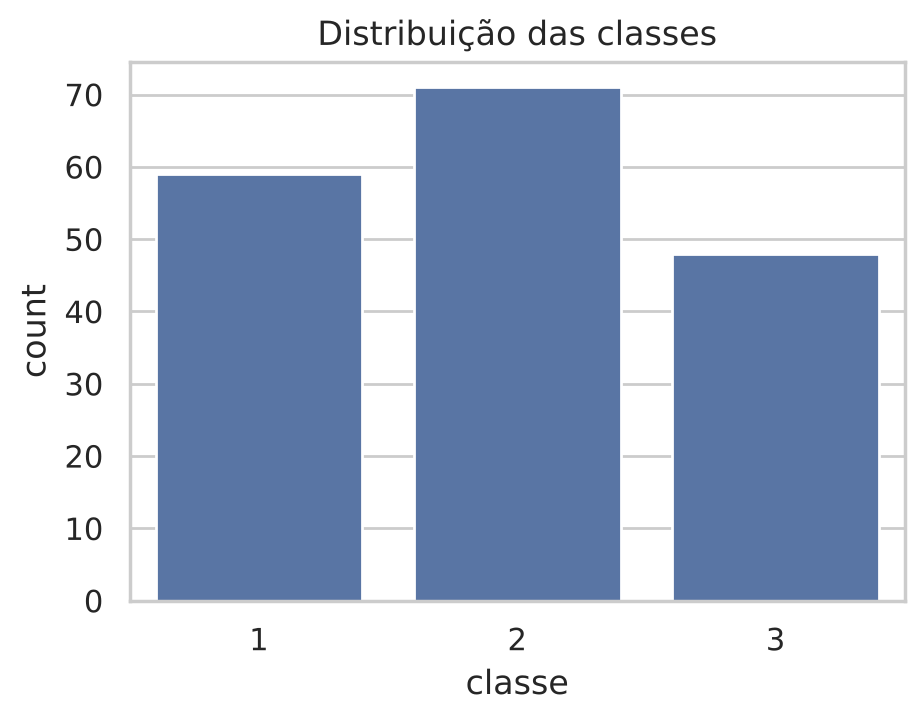

In [5]:
print("Distribuição das classes (1, 2 e 3 = cultivares):")
dist = df["classe"].value_counts().sort_index()
display(pd.DataFrame({"quantidade": dist, "percentual": (dist / len(df) * 100).round(1)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="classe", ax=ax)
ax.set_title("Distribuição das classes")
plt.show()

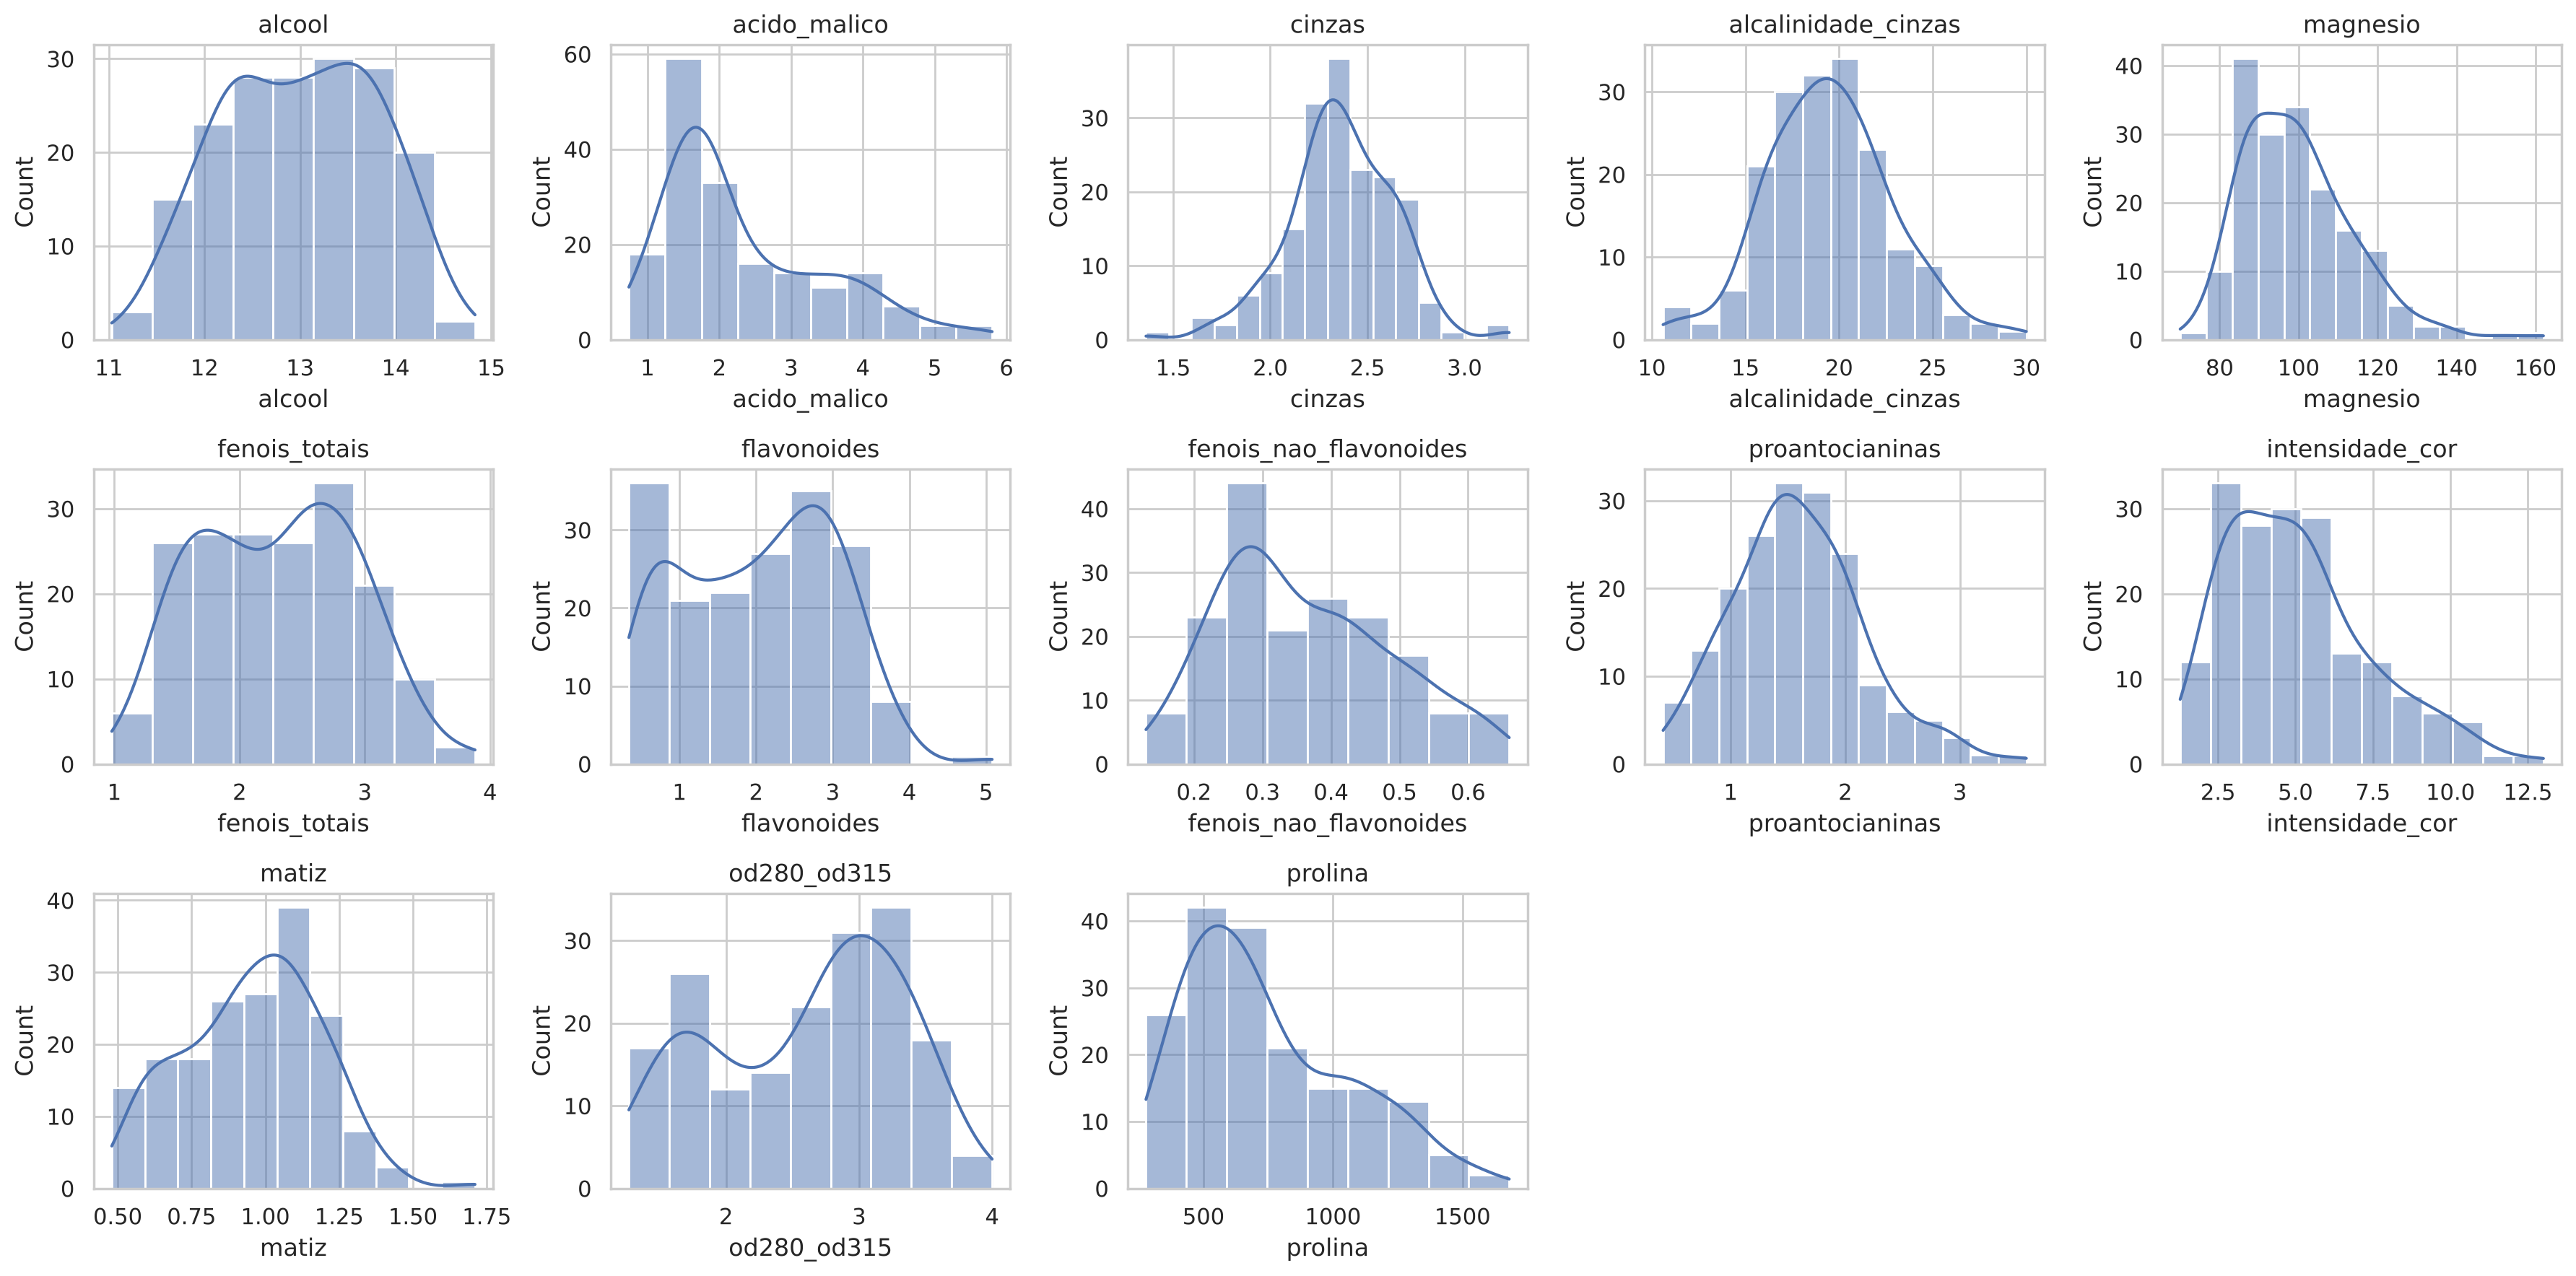

In [6]:
fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for ax, col in zip(axes.ravel(), COLUNAS[1:]):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(COLUNAS) - 1:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

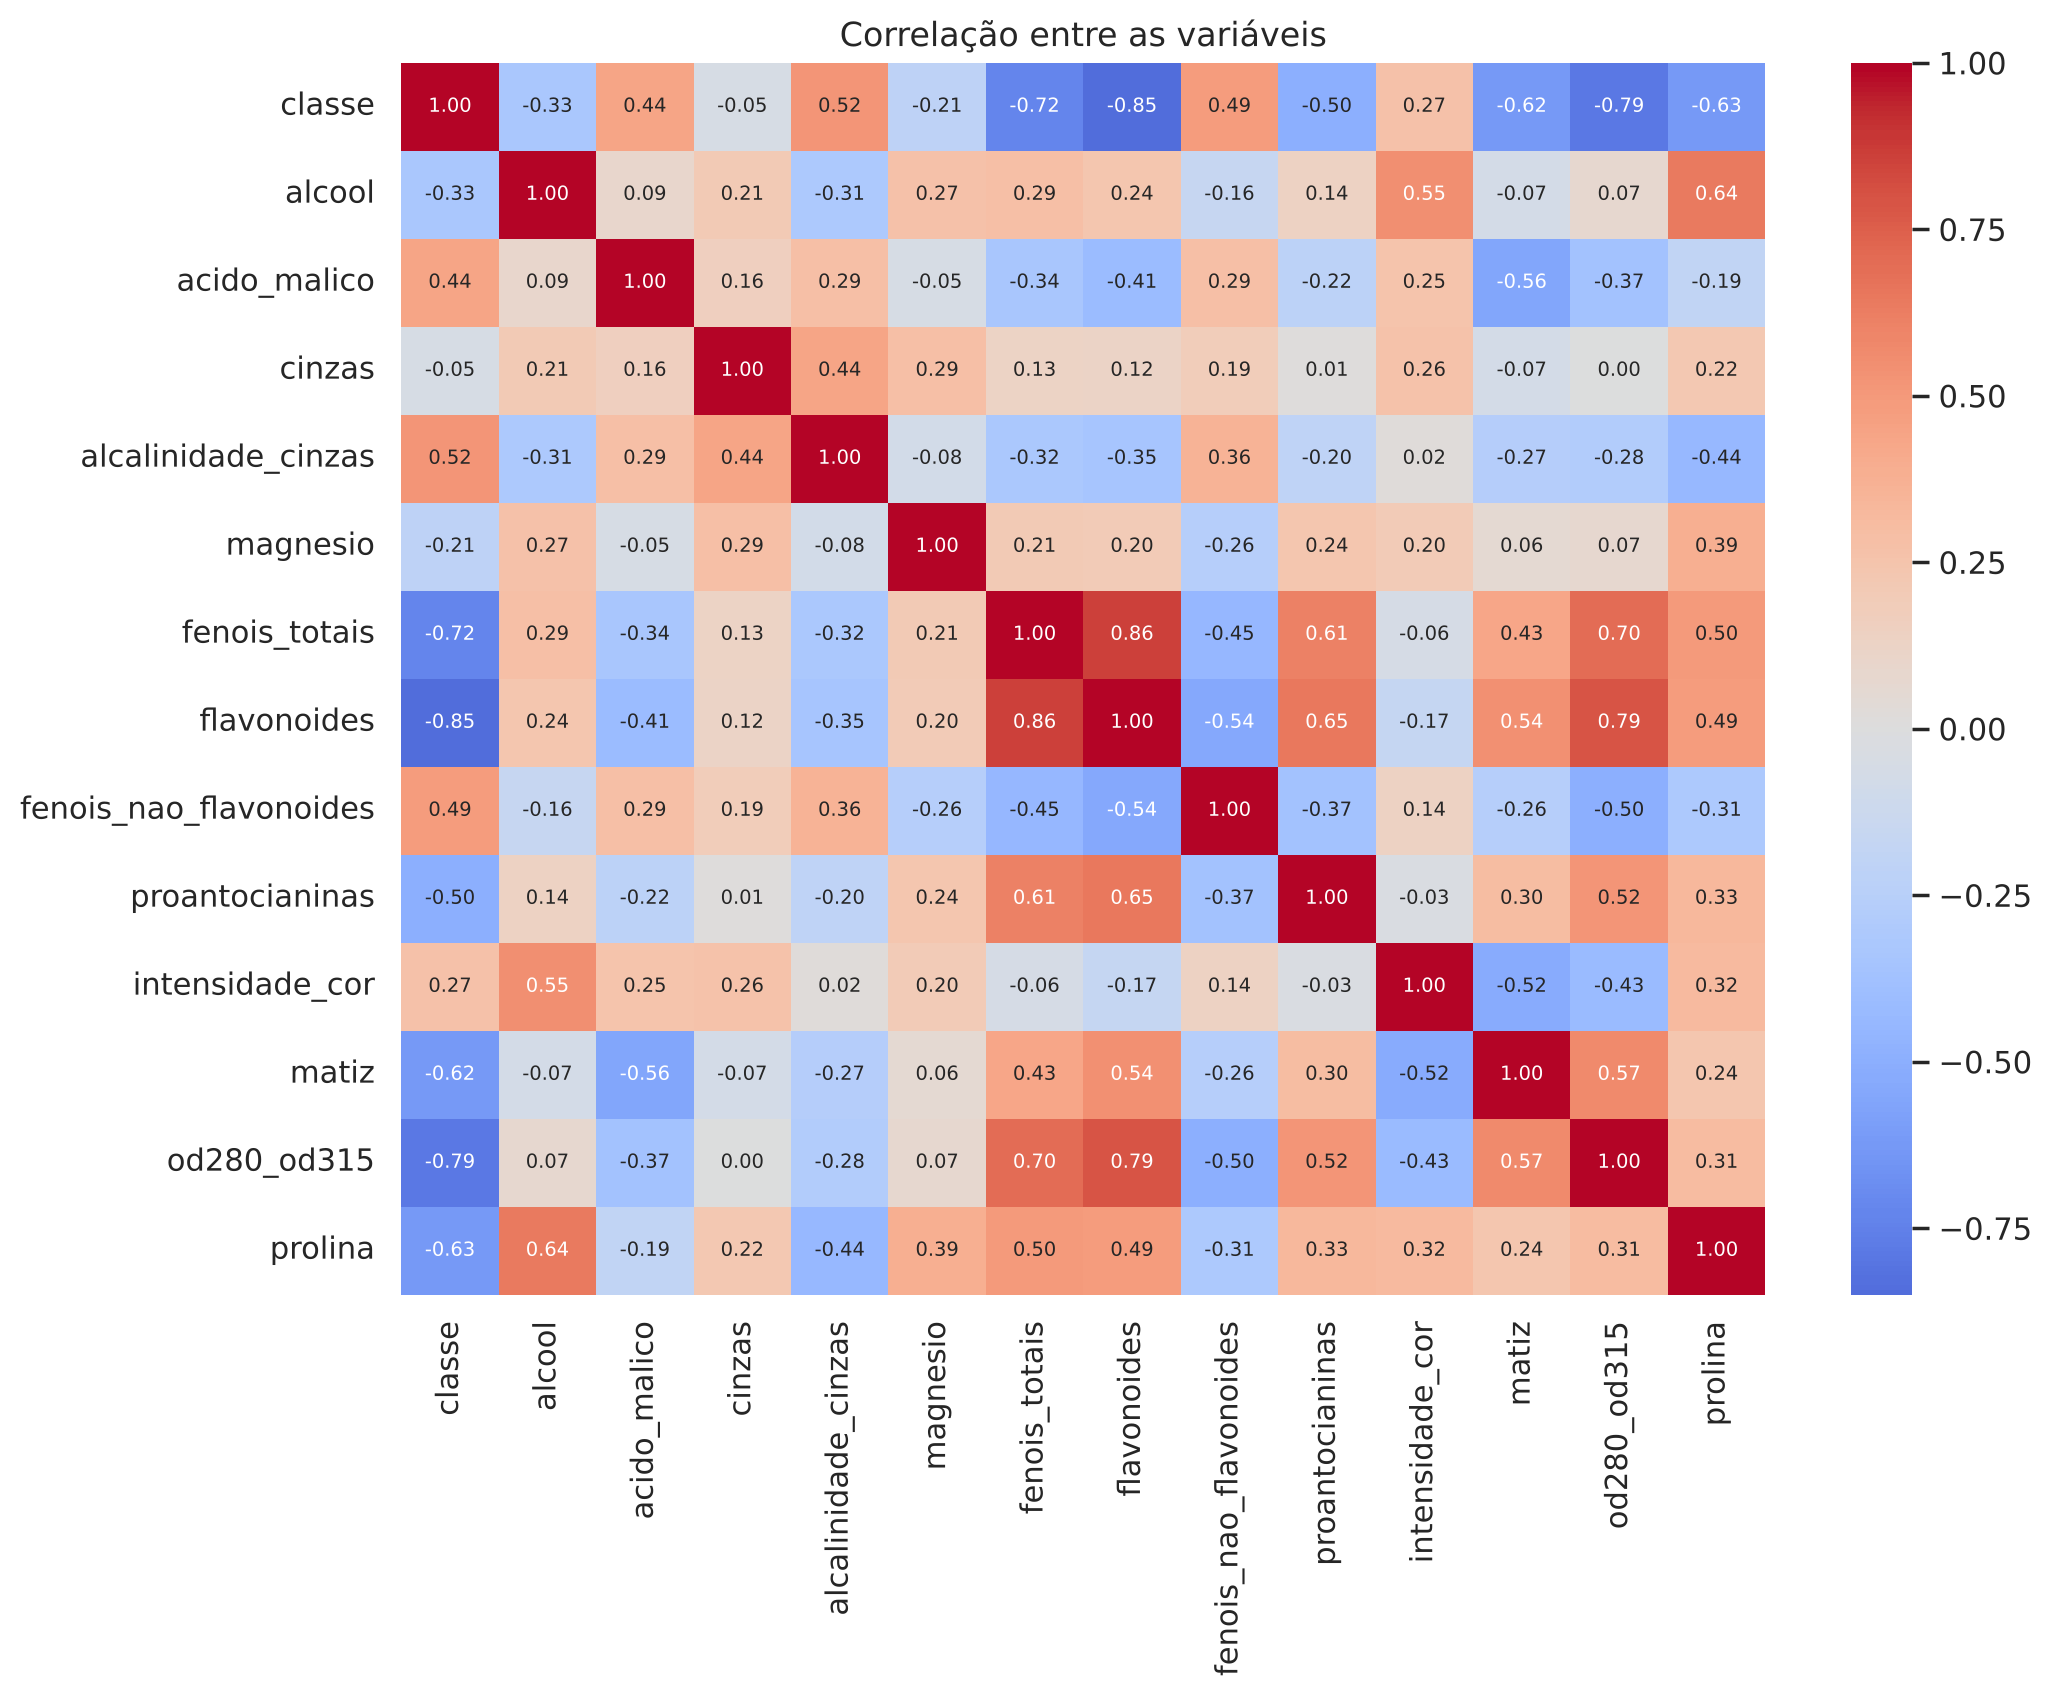

In [7]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr().round(2), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlação entre as variáveis")
plt.show()

## 3. Transformação nas colunas

Transformações aplicadas:

- **Rótulo:** a classe original é 1, 2, 3; foi convertida para 0, 1, 2 (padrão esperado pelo scikit-learn).
- **Transformação logarítmica em `prolina`:** é a variável com maior escala (centenas a milhares) e distribuição assimétrica; `log1p` reduz a assimetria.
- **Padronização (StandardScaler):** todas as variáveis ficam com média 0 e desvio 1. Ela é aplicada **dentro do pipeline do modelo** (seção 6), ajustada somente com o conjunto de treino, para evitar vazamento de dados (*data leakage*) para validação e teste.

In [8]:
df_col = df.copy()

# 1) Rótulo de 1..3 para 0..2
df_col["classe"] = df_col["classe"] - 1

# 2) Log na prolina (variável assimétrica e de grande escala)
assim_antes = df_col["prolina"].skew()
df_col["prolina"] = np.log1p(df_col["prolina"])
assim_depois = df_col["prolina"].skew()

print(f"Assimetria da prolina: antes = {assim_antes:.2f} | depois = {assim_depois:.2f}")
df_col.head()

Assimetria da prolina: antes = 0.77 | depois = 0.09


,classe,alcool,acido_malico,cinzas,alcalinidade_cinzas,magnesio,fenois_totais,flavonoides,fenois_nao_flavonoides,proantocianinas,intensidade_cor,matiz,od280_od315,prolina
0,0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,6.971669
1,0,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,6.957497
2,0,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,7.078342
3,0,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,7.300473
4,0,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,6.601230


## 4. Transformação nas linhas

Transformações aplicadas:

- **Remoção de linhas duplicadas.**
- **Remoção de outliers** pelo critério do IQR com fator 2,0 (um valor mais permissivo que o usual 1,5, pois a base é pequena e o fator 1,5 removeria cerca de 10% das amostras).
- **Embaralhamento das linhas:** o arquivo original está ordenado por classe.

In [9]:
df_lin = df_col.copy()
n_inicial = len(df_lin)

# 1) Duplicatas
df_lin = df_lin.drop_duplicates()
n_dup = n_inicial - len(df_lin)

# 2) Outliers extremos (IQR * 2) nas variáveis numéricas
features = [c for c in df_lin.columns if c != "classe"]
Q1 = df_lin[features].quantile(0.25)
Q3 = df_lin[features].quantile(0.75)
IQR = Q3 - Q1
limite_inf = Q1 - 2.0 * IQR
limite_sup = Q3 + 2.0 * IQR
eh_outlier = ((df_lin[features] < limite_inf) | (df_lin[features] > limite_sup)).any(axis=1)
print("Linhas com outlier:", int(eh_outlier.sum()))
df_lin = df_lin[~eh_outlier]

# 3) Embaralhar
df_lin = df_lin.sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f"Linhas iniciais: {n_inicial} | duplicadas removidas: {n_dup} | outliers removidos: {int(eh_outlier.sum())} | finais: {len(df_lin)}")
print("\nDistribuição das classes após limpeza:")
print(df_lin["classe"].value_counts().sort_index().to_string())

Linhas com outlier: 5
Linhas iniciais: 178 | duplicadas removidas: 0 | outliers removidos: 5 | finais: 173

Distribuição das classes após limpeza:
classe
0    59
1    67
2    47


## 5. Divisão em treino, validação e teste

Divisão **estratificada** (mantém a proporção das classes): **60% treino / 20% validação / 20% teste**.

- **Treino:** ajusta os modelos.
- **Validação:** compara modelos e escolhe o melhor.
- **Teste:** usado uma única vez, no final, para estimar o desempenho real.

In [10]:
X = df_lin[features]
y = df_lin["classe"]

X_treino, X_temp, y_treino, y_temp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=SEED)
X_val, X_teste, y_val, y_teste = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

resumo = pd.DataFrame({
    "linhas": [len(X_treino), len(X_val), len(X_teste)],
    "percentual": [round(len(d) / len(X) * 100, 1) for d in (X_treino, X_val, X_teste)],
}, index=["treino", "validação", "teste"])
display(resumo)

print("\nClasses por subconjunto:")
display(pd.DataFrame({
    "treino": y_treino.value_counts().sort_index(),
    "validação": y_val.value_counts().sort_index(),
    "teste": y_teste.value_counts().sort_index(),
}))

,linhas,percentual
treino,103,59.5
validação,35,20.2
teste,35,20.2



Classes por subconjunto:


,treino,validação,teste
classe,,,
0,35,12,12
1,40,13,14
2,28,10,9


## 6. Treinamento e avaliação do modelo

Três algoritmos são treinados com o conjunto de **treino** e comparados no conjunto de **validação**. O melhor é o modelo final. Todos usam um `Pipeline` com `StandardScaler`.

In [11]:
candidatos = {
    "Regressão Logística": LogisticRegression(max_iter=1000, random_state=SEED),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
}

resultados = []
modelos = {}
for nome, clf in candidatos.items():
    pipe = Pipeline([("padronizacao", StandardScaler()), ("modelo", clf)])
    pipe.fit(X_treino, y_treino)
    modelos[nome] = pipe
    resultados.append({
        "modelo": nome,
        "acuracia_treino": accuracy_score(y_treino, pipe.predict(X_treino)),
        "acuracia_validacao": accuracy_score(y_val, pipe.predict(X_val)),
    })

tabela = pd.DataFrame(resultados).set_index("modelo").round(4)
display(tabela)

melhor_nome = tabela["acuracia_validacao"].idxmax()
print("Modelo escolhido pela validação:", melhor_nome)

,acuracia_treino,acuracia_validacao
modelo,,
Regressão Logística,1.0000,0.9714
KNN (k=5),0.9709,0.9714
Random Forest,1.0000,1.0000


Modelo escolhido pela validação: Random Forest


## 7. Avaliação final no conjunto de teste

O modelo escolhido é avaliado no conjunto de teste, que não foi usado em nenhuma decisão anterior.

Modelo: Random Forest
Acurácia no teste: 0.9714 (97.14%)  —  34 acertos em 35 amostras


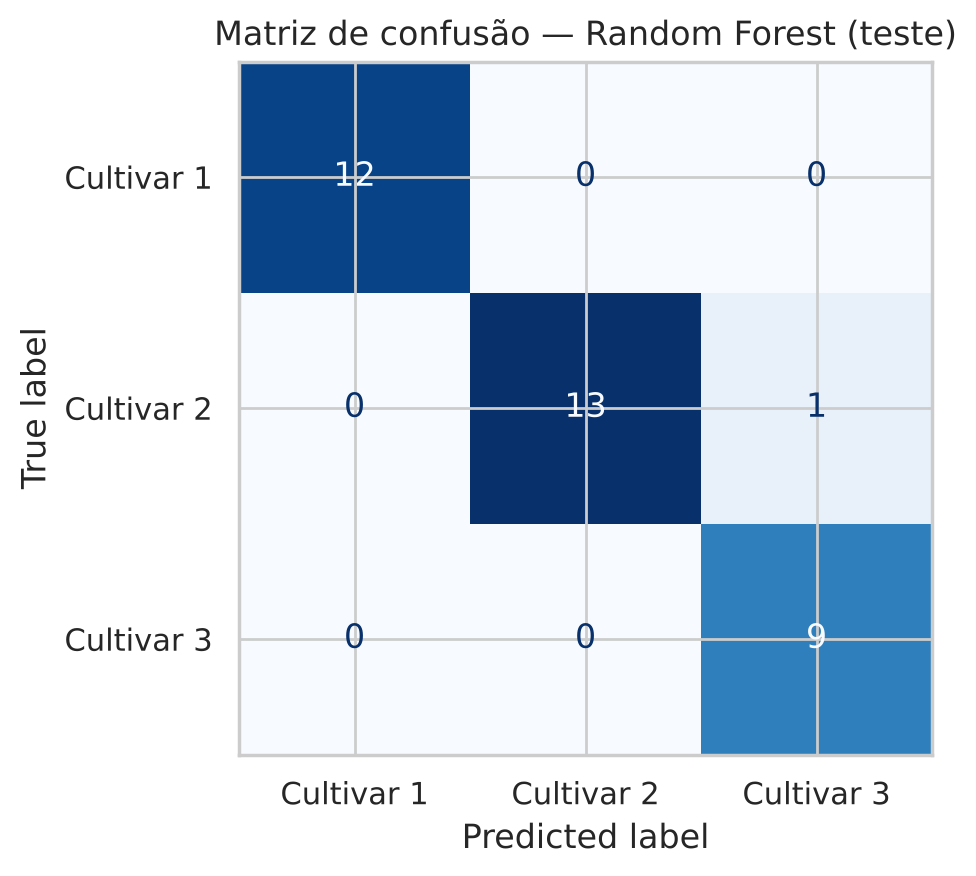


Relatório por classe:
              precision    recall  f1-score   support

  Cultivar 1      1.000     1.000     1.000        12
  Cultivar 2      1.000     0.929     0.963        14
  Cultivar 3      0.900     1.000     0.947         9

    accuracy                          0.971        35
   macro avg      0.967     0.976     0.970        35
weighted avg      0.974     0.971     0.972        35



In [12]:
modelo_final = modelos[melhor_nome]
y_pred = modelo_final.predict(X_teste)

acc = accuracy_score(y_teste, y_pred)
print(f"Modelo: {melhor_nome}")
print(f"Acurácia no teste: {acc:.4f} ({acc*100:.2f}%)  —  {int((y_pred == y_teste).sum())} acertos em {len(y_teste)} amostras")

cm = confusion_matrix(y_teste, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Cultivar 1", "Cultivar 2", "Cultivar 3"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusão — {melhor_nome} (teste)")
plt.show()

print("\nRelatório por classe:")
print(classification_report(y_teste, y_pred, target_names=["Cultivar 1", "Cultivar 2", "Cultivar 3"], digits=3))

> **Observação:** o conjunto de teste tem poucas amostras (a base completa tem 178), então a acurácia varia bastante com a divisão feita. Por isso, abaixo é feita uma validação cruzada estratificada como verificação extra de robustez.

In [13]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scores = cross_val_score(modelos[melhor_nome], X, y, cv=cv, scoring="accuracy")
print("Acurácia em 5 folds:", scores.round(3))
print(f"Média: {scores.mean():.3f}  |  Desvio: {scores.std():.3f}")

Acurácia em 5 folds: [1.    1.    0.914 0.971 1.   ]
Média: 0.977  |  Desvio: 0.033


## 8. Implantação e predição

O modelo final (pipeline completo, incluindo a padronização) é salvo em arquivo e **carregado de volta**, simulando o uso em produção. Em seguida, é feita a predição para um vinho novo, informado com as medidas químicas **originais** (a transformação de `prolina` é aplicada antes, igual ao treino).

In [14]:
joblib.dump(modelo_final, "modelo_vinho.joblib")
modelo_implantado = joblib.load("modelo_vinho.joblib")
print("Modelo salvo e carregado: modelo_vinho.joblib")

Modelo salvo e carregado: modelo_vinho.joblib


In [15]:
def prever_vinho(medidas: dict):
    """Recebe as medidas químicas originais de um vinho e devolve a cultivar prevista."""
    entrada = pd.DataFrame([medidas])[features].copy()
    entrada["prolina"] = np.log1p(entrada["prolina"])   # mesma transformação do treino
    classe = int(modelo_implantado.predict(entrada)[0])
    probs = modelo_implantado.predict_proba(entrada)[0]
    return classe + 1, probs

# Vinho novo (medidas químicas originais)
novo_vinho = {
    "alcool": 13.20, "acido_malico": 1.78, "cinzas": 2.14, "alcalinidade_cinzas": 11.2,
    "magnesio": 100, "fenois_totais": 2.65, "flavonoides": 2.76, "fenois_nao_flavonoides": 0.26,
    "proantocianinas": 1.28, "intensidade_cor": 4.38, "matiz": 1.05, "od280_od315": 3.40, "prolina": 1050,
}

cultivar, probs = prever_vinho(novo_vinho)
print("Entrada:", novo_vinho)
print(f"\n>>> Cultivar prevista: {cultivar}")
for i, p in enumerate(probs, start=1):
    print(f"    Probabilidade cultivar {i}: {p*100:.1f}%")

Entrada: {'alcool': 13.2, 'acido_malico': 1.78, 'cinzas': 2.14, 'alcalinidade_cinzas': 11.2, 'magnesio': 100, 'fenois_totais': 2.65, 'flavonoides': 2.76, 'fenois_nao_flavonoides': 0.26, 'proantocianinas': 1.28, 'intensidade_cor': 4.38, 'matiz': 1.05, 'od280_od315': 3.4, 'prolina': 1050}

>>> Cultivar prevista: 1
    Probabilidade cultivar 1: 98.5%
    Probabilidade cultivar 2: 1.0%
    Probabilidade cultivar 3: 0.5%


## Conclusão

- A esteira cobre todas as etapas: carga, estatísticas descritivas, transformações em colunas e linhas, divisão treino/validação/teste, treinamento, avaliação (matriz de confusão e acurácia) e predição com o modelo salvo.
- A escolha do modelo foi feita **somente pela validação**; o teste foi usado apenas uma vez no final.
- Limitação: a base é pequena e "bem comportada" (as classes são bem separáveis), então a alta acurácia não deve ser extrapolada para dados reais de outras regiões ou safras.